<a href="https://colab.research.google.com/github/rozadoesn-stack/ML-Basic/blob/main/NLP_NER_BERT_12_10_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Основано на [тьюториале](https://github.com/huggingface/notebooks/blob/master/examples/token_classification.ipynb).

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="huggingface_hub")

In [ ]:
# В Colab уже предустановлены torch, transformers, datasets, scikit-learn и pandas.
# Доустанавливаем только razdel (токенизация на слова).
# corus, evaluate и seqeval больше не нужны: corus не импортируется на Python 3.13
# (модуль cgi удалён из стандартной библиотеки), а seqeval не обновлялся с 2020 года
# и больше не собирается из исходников в свежем Colab.
!pip install -q razdel datasets

В этом блокноте мы дообучаем модель на задаче классификации отдельных слов, а именно, распознавание именованных сущностей (aka named entity recognition, aka NER). Мы возьмём датасет медицинских сущностей, но в целом пайплайн подходит для любой задачи на выделение сущностей в тексте.

Для скорости мы возьмём маленький BERT для русского языка [rubert-tiny](https://huggingface.co/cointegrated/rubert-tiny2); если взять другую, более крупную BERT-подобную модель, качество NER может быть выше, но и время обучения и работы будет дольше


In [ ]:
import transformers, datasets, torch, sklearn, sys
from transformers import set_seed

SEED = 42
set_seed(SEED)  # фиксируем random / numpy / torch для воспроизводимости

model_checkpoint = "cointegrated/rubert-tiny2"
batch_size = 16
num_train_epochs = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | "
      f"transformers {transformers.__version__} | datasets {datasets.__version__} | "
      f"sklearn {sklearn.__version__} | device: {device}")

python 3.13.16 | torch 2.11.0+cpu | transformers 5.18.0 | datasets 4.8.5 | sklearn 1.6.1 | device: cpu


## Загрузим датасет

Для обучения мы возьмём [Russian Drug Reaction Corpus](https://github.com/cimm-kzn/RuDReC): размеченный корпус русскоязычных отзывов на лекарства.

Файл хранится в формате JSON Lines: одна строка — одно предложение с текстом и списком сущностей (тип и позиции в символах). Раньше мы читали его библиотекой `corus`, но она перестала импортироваться на Python 3.13, поэтому напишем загрузчик сами — это несколько строк.

In [ ]:
!wget -q -nc https://raw.githubusercontent.com/cimm-kzn/RuDReC/master/data/rudrec_annotated.json
!ls -lh rudrec_annotated.json

-rw-r--r-- 1 root root 1.7M Oct 11 06:53 rudrec_annotated.json


In [ ]:
import json
from dataclasses import dataclass, field


@dataclass
class RuDReCEntity:
    entity_id: str
    entity_text: str
    entity_type: str
    start: int
    end: int
    concept_id: str | None = None


@dataclass
class RuDReCRecord:
    file_name: str
    text: str
    sentence_id: int
    entities: list = field(default_factory=list)


def load_rudrec(path):
    with open(path, encoding="utf-8") as f:
        for line in f:
            item = json.loads(line)  # json понимает NaN, который встречается в файле
            entities = [
                RuDReCEntity(e["entity_id"], e["entity_text"], e["entity_type"],
                             e["start"], e["end"], e.get("concept_id"))
                for e in item["entities"]
            ]
            yield RuDReCRecord(item["file_name"], item["text"], item["sentence_id"], entities)


drugs = list(load_rudrec("rudrec_annotated.json"))
print(len(drugs))

4809


Пример документа:

In [ ]:
type(drugs[0]), len(drugs[0].entities)

(__main__.RuDReCRecord, 4)

In [ ]:
drugs[0]

RuDReCRecord(file_name='172744.tsv', text='нам прописали, так мой ребенок сыпью покрылся, глаза опухли, сверху и снизу на веках высыпала сыпь, ( 8 месяцев сыну)А от виферона такого не было... У кого ещё такие побочки, отзовитесь!1 Чем спасались?\n', sentence_id=0, entities=[RuDReCEntity(entity_id='*[0]_se', entity_text='виферона', entity_type='Drugform', start=122, end=130, concept_id='C0021735'), RuDReCEntity(entity_id='*[1]', entity_text='сыпью покрылся', entity_type='ADR', start=31, end=45, concept_id='C0015230'), RuDReCEntity(entity_id='*[2]', entity_text='глаза опухли', entity_type='ADR', start=47, end=59, concept_id='C4760994'), RuDReCEntity(entity_id='*[3]', entity_text='на веках высыпала сыпь', entity_type='ADR', start=76, end=98, concept_id='C0015230')])

Посмотрим, какие сущности есть: лекарства, форма лекарств, класс лекарств, показания к применению, побочки, и прочие болезни/симптомы.

https://arxiv.org/abs/2004.03659

* **DRUGNAME** Название/бренд препарата или его ингредиенты/активные соединения.
* **DRUGCLASS** Класса лекарства (противовоспалительное,
сердечно-сосудистое и т. п.).
* **DRUGFORM** Форма препарата (таблетки, сироп и т. п.).
* **DI = Drug Indication** Любые симптомы, которые могли быть показанием к назначению препарата.
* **ADR = Adverse Drug Reaction** Побочные эффекты от приема препарата.
* **FINDING** Любые побочные эффекты, напрямую не связанные с приемом препарата или исходной болезнью, которые наблюдались у пациента.


In [ ]:
from collections import Counter, defaultdict
type2text = defaultdict(Counter)
ents = Counter()
for item in drugs:
    for e in item.entities:
        ents[e.entity_type] += 1
        type2text[e.entity_type][e.entity_text] += 1

for k, v in ents.most_common():
    print(k, v)
    print(type2text[k].most_common(5))

DI 1401
[('простуды', 64), ('ОРВИ', 47), ('профилактики', 42), ('гриппа', 34), ('насморк', 30)]
Drugname 1043
[('Виферон', 33), ('Анаферон', 25), ('Циклоферон', 24), ('валерианы', 14), ('Ликопид', 12)]
Drugform 836
[('таблетки', 154), ('таблеток', 79), ('свечи', 63), ('мазь', 34), ('капли', 30)]
ADR 720
[('аллергия', 16), ('слабость', 13), ('диарея', 12), ('температура', 11), ('головная боль', 10)]
Drugclass 330
[('противовирусный', 21), ('противовирусное', 18), ('противовирусных', 13), ('противовирусные', 12), ('антибиотик', 11)]
Finding 236
[('аллергии', 12), ('температуры', 6), ('сонливости', 5), ('гриппа', 5), ('ОРВИ', 4)]


In [ ]:
drugs[0].text

'нам прописали, так мой ребенок сыпью покрылся, глаза опухли, сверху и снизу на веках высыпала сыпь, ( 8 месяцев сыну)А от виферона такого не было... У кого ещё такие побочки, отзовитесь!1 Чем спасались?\n'

Напишем функцию, перекладывающую разметку сущностей на уровень слов. Будем использовать [IOB](https://en.wikipedia.org/wiki/Inside–outside–beginning_(tagging))-нотацию, чтобы разделять несколько сущностей одного типа, идущих подряд.

In [ ]:
from razdel import tokenize

def extract_labels(item):
    raw_toks = list(tokenize(item.text)) #tokenize - разбиение на слова здесь!
    words = [tok.text for tok in raw_toks]
    word_labels = ['O'] * len(raw_toks)
    char2word = [None] * len(item.text)
    for i, word in enumerate(raw_toks):
        char2word[word.start:word.stop] = [i] * len(word.text)

    for e in item.entities:
        e_words = sorted({idx for idx in char2word[e.start:e.end] if idx is not None})
        word_labels[e_words[0]] = 'B-' + e.entity_type
        for idx in e_words[1:]:
            word_labels[idx] = 'I-' + e.entity_type

    return {'tokens': words, 'tags': word_labels}

In [ ]:
print(extract_labels(drugs[0])['tags'])

['O', 'O', 'O', 'O', 'O', 'O', 'B-ADR', 'I-ADR', 'O', 'B-ADR', 'I-ADR', 'O', 'O', 'O', 'O', 'B-ADR', 'I-ADR', 'I-ADR', 'I-ADR', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-Drugform', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


In [ ]:
print(extract_labels(drugs[0])['tokens'])

['нам', 'прописали', ',', 'так', 'мой', 'ребенок', 'сыпью', 'покрылся', ',', 'глаза', 'опухли', ',', 'сверху', 'и', 'снизу', 'на', 'веках', 'высыпала', 'сыпь', ',', '(', '8', 'месяцев', 'сыну', ')', 'А', 'от', 'виферона', 'такого', 'не', 'было', '...', 'У', 'кого', 'ещё', 'такие', 'побочки', ',', 'отзовитесь', '!', '1', 'Чем', 'спасались', '?']


In [ ]:
from sklearn.model_selection import train_test_split
ner_data = [extract_labels(item) for item in drugs]
ner_train, ner_test = train_test_split(ner_data, test_size=0.2, random_state=1)

Пример данных

In [ ]:
import pandas as pd
pd.options.display.max_colwidth = 300
pd.DataFrame(ner_train).sample(3)

,tokens,tags
3692,"[Мочить, плечо, запретили, .]","[O, O, O, O]"
184,"[Горло, как, было, красное, так, и, осталось, .]","[B-DI, I-DI, I-DI, I-DI, O, O, O, O]"
1621,"[Одной, упаковкой, не, обойтись, .]","[O, O, O, O, O]"


Соберём все виды меток в список.

In [ ]:
label_list = sorted({label for item in ner_train for label in item['tags']})
if 'O' in label_list:
    label_list.remove('O')
    label_list = ['O'] + label_list
label_list

['O',
 'B-ADR',
 'B-DI',
 'B-Drugclass',
 'B-Drugform',
 'B-Drugname',
 'B-Finding',
 'I-ADR',
 'I-DI',
 'I-Drugclass',
 'I-Drugform',
 'I-Drugname',
 'I-Finding']

Сложим наши данные в объект [`DatasetDict`](https://huggingface.co/docs/datasets/package_reference/main_classes.html#datasetdict), нативный для huggingface.

In [ ]:
from datasets import Dataset, DatasetDict

In [ ]:
ner_data = DatasetDict({
    'train': Dataset.from_pandas(pd.DataFrame(ner_train)),
    'test': Dataset.from_pandas(pd.DataFrame(ner_test))
})
ner_data

DatasetDict({
    train: Dataset({
        features: ['tokens', 'tags'],
        num_rows: 3847
    })
    test: Dataset({
        features: ['tokens', 'tags'],
        num_rows: 962
    })
})

## Предобработка данных

Прежде чем мы сможем подать тексты на вход модели, их нужно предобработать. Сделать это можно с помощью токенизатора `Transformers`, который токенизирует входные данные и преобразует их в формат, ожидаемый моделью, а также генерирует другие входные данные, которые которые необходимы для работы модели.

Для этого воспользуемся классов `AutoTokenizer.from_pretrained`.

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

Вызов токенизатора осуществляется в одну строчку:

In [ ]:
tokenizer("Привет, это одно предложение!")

{'input_ids': [2, 51343, 16, 2389, 13305, 24889, 5, 3], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}



Если, как в нашем случае, входные данные уже были разделены на слова, нужно передать токенизатору список слов с аргументом `is_split_into_words=True`.

In [ ]:
tokenizer(["Привет", ",", "это", "одно", "предложение", ",", "разбитое", "на", "слова", "."], is_split_into_words=True)

{'input_ids': [2, 51343, 16, 2389, 13305, 24889, 16, 52423, 626, 548, 7851, 18, 3], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

Вернемся к исходному формату.

In [ ]:
tokenized_input = tokenizer("Привет, это одно предложение!", is_split_into_words=False)
tokens = tokenizer.convert_ids_to_tokens(tokenized_input["input_ids"])
print(tokens)

['[CLS]', 'Привет', ',', 'это', 'одно', 'предложение', '!', '[SEP]']


In [ ]:
tokenized_input = tokenizer(["Привет", ",", "это", "одно", "предложение", ",", "разбитое", "на", "слова", "."], is_split_into_words=True)
tokens = tokenizer.convert_ids_to_tokens(tokenized_input["input_ids"])
print(tokens)

['[CLS]', 'Привет', ',', 'это', 'одно', 'предложение', ',', 'разбито', '##е', 'на', 'слова', '.', '[SEP]']


In [ ]:
tokenized_input["input_ids"]

[2, 51343, 16, 2389, 13305, 24889, 16, 52423, 626, 548, 7851, 18, 3]

Чтобы перейти с уровня слов на уровень subword tokens, нужно ещё раз предобработать тексты.

In [ ]:
print(tokenized_input.word_ids())

[None, 0, 1, 2, 3, 4, 5, 6, 6, 7, 8, 9, None]


In [ ]:
example = ner_train[2]
print(example["tokens"])


['Мой', 'мозг', 'не', 'может', 'постичь', 'творческий', 'полет', 'мыслей', 'создателей', 'сего', 'сиропа', '.']


In [ ]:
tokenized_input = tokenizer(['Мой', 'мозг', 'не', 'может', 'постичь', 'творческий', 'полет', 'мыслей', 'создателей', 'сего', 'сиропа', '.'], is_split_into_words=True)
tokenizer.convert_ids_to_tokens(tokenized_input["input_ids"])

['[CLS]',
 'Мой',
 'мозг',
 'не',
 'может',
 'пости',
 '##чь',
 'творческий',
 'полет',
 'мыслей',
 'создателей',
 'сего',
 'сиро',
 '##па',
 '.',
 '[SEP]']

'сиропа' -> 'B-Drugform'

'сиро', '##па',

'B-Drugform', 'B-Drugform'


'B-Drugform', '-100'

In [ ]:
word_ids = tokenized_input.word_ids()
aligned_labels = [-100 if i is None else example["tags"][i] for i in word_ids]
print(len(aligned_labels), len(tokenized_input["input_ids"]))

16 16


In [ ]:
aligned_labels

[-100,
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'B-Drugform',
 'B-Drugform',
 'O',
 -100]

In [ ]:
tokenized_input["input_ids"]

[2,
 33249,
 35936,
 769,
 3960,
 66413,
 13041,
 44525,
 44274,
 38032,
 46743,
 49149,
 77209,
 3490,
 18,
 3]

Сопоставим специальным токенам лейблы -100 (этот индекс игнорируется PyTorch), а всем остальным токенам поставим в соотвествие лейблы тех слов, к которым они относятся. Другая стратегия - сопоставить лейбл только для первого токена каждого слова, а остальным присвоить метку -100. Как показывает практика, вторая стратегия обычно работает лучше. Реализуем обе стратегии, а переключаться между ними будем с помощью флага `label_all_tokens`.

In [ ]:
# Мезим Форте -> B-Drugname, I-Drugname
# [CLS] Мезим Форте [SEP]-> -100, B-Drugname, I-Drugname, -100
#'[CLS]' -100, 'Ме' B-Drugname, '##зи' -100, '##м' -100, 'Форт' I-Drugname, '##е' -100, '[SEP] -100'
# -100, B-Drugname, -100, -100, I-Drugname, -100, -100

In [ ]:
def tokenize_and_align_labels(examples, label_all_tokens=False):
    tokenized_inputs = tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)

    labels = []
    for i, label in enumerate(examples['tags']):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            # Special tokens have a word id that is None. We set the label to -100 so they are automatically
            # ignored in the loss function.
            if word_idx is None:
                label_ids.append(-100)

            # We set the label for the first token of each word.
            elif word_idx != previous_word_idx:
                label_ids.append(label[word_idx])
            # For the other tokens in a word, we set the label to either the current label or -100, depending on
            # the label_all_tokens flag.
            else:
                label_ids.append(label[word_idx] if label_all_tokens else -100)
            previous_word_idx = word_idx

        label_ids = [label_list.index(idx) if isinstance(idx, str) else idx for idx in label_ids]

        labels.append(label_ids)

    tokenized_inputs["labels"] = labels
    return tokenized_inputs

Функция способна работать с одним или несколькими примерами. В случае нескольких примеров токенизатор вернет список списков для каждого ключа:

In [ ]:
tokenize_and_align_labels(ner_data['train'][22:23])

{'input_ids': [[2, 1041, 37038, 33265, 19106, 40305, 22018, 548, 22276, 320, 21538, 16, 47886, 548, 59614, 11137, 626, 56606, 700, 18, 3]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], 'labels': [[-100, 0, 0, 0, 0, 1, -100, 7, 7, 7, 7, 0, 0, 0, 0, -100, -100, 0, -100, 0, -100]]}

In [ ]:
ner_data['train'][22:23]

{'tokens': [['На',
   'следующее',
   'утро',
   'появились',
   'высыпания',
   'на',
   'лице',
   'и',
   'руках',
   ',',
   'похожие',
   'на',
   'комариные',
   'укусы',
   '.']],
 'tags': [['O',
   'O',
   'O',
   'O',
   'B-ADR',
   'I-ADR',
   'I-ADR',
   'I-ADR',
   'I-ADR',
   'O',
   'O',
   'O',
   'O',
   'O',
   'O']]}

Применим данную функцию предобработки ко всему датасету.

In [ ]:
tokenized_datasets = ner_data.map(tokenize_and_align_labels, batched=True)

Map:   0%|          | 0/3847 [00:00<?, ? examples/s]

Map:   0%|          | 0/962 [00:00<?, ? examples/s]

## Fine-tuning the model

В данном случае мы решаем задачу Sequence Labeling, поэтому для дообучения модели воспользуемся классем `AutoModelForTokenClassification`. Он добавляет линейный слой, который применяется к выходам со всех токенов.

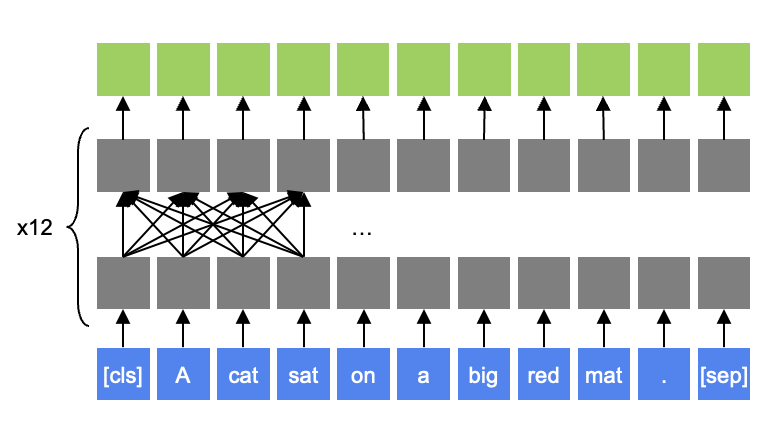

Если бы мы писали код для дообучения BERT под задачу Sequence Labeling самостоятельно, то он бы выглядел так.



```
class SimpleBertForTokenClassification(nn.Module):
    def __init__(self, num_labels=9):
        super().__init__()
        # Загружаем предобученный BERT
        self.bert = BertModel.from_pretrained("bert-base-uncased")
        hidden_size = self.bert.config.hidden_size
        
        # Один общий линейный слой для всех токенов
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, input_ids, attention_mask=None, labels=None):
        # Получаем выходы BERT: last_hidden_state имеет размер [batch_size, seq_len, hidden_size]
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        sequence_output = outputs.last_hidden_state
        
        # Применяем линейный слой к каждому токену
        logits = self.classifier(sequence_output)  # [batch_size, seq_len, num_labels]
        
        loss = None
        if labels is not None:
            # Игнорируем паддинги (-100 по соглашению Hugging Face)
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(
                logits.view(-1, self.classifier.out_features),
                labels.view(-1)
            )
        
        return {"loss": loss, "logits": logits}
```



In [ ]:
len(label_list)

13

In [ ]:
from transformers import AutoModelForTokenClassification, TrainingArguments, Trainer

model = AutoModelForTokenClassification.from_pretrained(model_checkpoint, num_labels=len(label_list))
model.config.id2label = dict(enumerate(label_list))
model.config.label2id = {v: k for k, v in model.config.id2label.items()}

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params we

Зададим параметры обучения с помощью класса [`TrainingArguments`](https://huggingface.co/transformers/main_classes/trainer.html#transformers.TrainingArguments).

In [ ]:
args = TrainingArguments(
    "ner",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=num_train_epochs,
    weight_decay=0.01,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)

Затем нам понадобится data collator для корректной обработки данных по батчам.

In [ ]:
from transformers import DataCollatorForTokenClassification

data_collator = DataCollatorForTokenClassification(tokenizer)

## Метрики качества NER

Считать качество NER по отдельным токенам неудобно: класс `O` занимает подавляющую часть токенов, и accuracy получается высокой даже у плохой модели. Поэтому стандартом является оценка **на уровне сущностей** (как в CoNLL-2003): сущность считается найденной, только если совпали **и её границы, и тип**.

- **precision** — доля предсказанных сущностей, которые есть в разметке;
- **recall** — доля сущностей из разметки, которые модель нашла;
- **f1** — их гармоническое среднее.

Раньше для этого использовали библиотеку `seqeval`, но она не обновлялась с 2020 года и больше не устанавливается в свежем Colab. Логика у неё простая, поэтому реализуем её сами: сначала достанем из IOB-последовательности список сущностей `(тип, начало, конец)`, а потом сравним множества сущностей.

In [ ]:
def get_entities(tags):
    """Извлекает сущности из IOB-разметки: список кортежей (тип, начало, конец включительно).

    Сущность начинается с B-X, а также с I-X, если перед ним стоит O или другой тип
    (так же поступают conlleval и seqeval по умолчанию).
    """
    entities = []
    ent_type, start = None, None
    for i, tag in enumerate(list(tags) + ["O"]):  # "O" в конце закрывает последнюю сущность
        prefix, _, label = tag.partition("-")
        starts_new = prefix == "B" or (prefix == "I" and label != ent_type)
        if ent_type is not None and (prefix == "O" or starts_new):
            entities.append((ent_type, start, i - 1))
            ent_type = None
        if starts_new:
            ent_type, start = label, i
    return entities


def entity_report(y_true, y_pred):
    """Precision/recall/f1 на уровне сущностей по каждому типу и в целом (micro).

    y_true, y_pred — списки предложений, каждое предложение — список IOB-меток.
    """
    true_ents, pred_ents = set(), set()
    for sent_id, (t, p) in enumerate(zip(y_true, y_pred)):
        true_ents |= {(sent_id, *e) for e in get_entities(t)}
        pred_ents |= {(sent_id, *e) for e in get_entities(p)}

    def prf(true_set, pred_set):
        tp = len(true_set & pred_set)
        precision = tp / len(pred_set) if pred_set else 0.0
        recall = tp / len(true_set) if true_set else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        return {"precision": precision, "recall": recall, "f1": f1, "support": len(true_set)}

    types = sorted({e[1] for e in true_ents | pred_ents})
    report = {t: prf({e for e in true_ents if e[1] == t}, {e for e in pred_ents if e[1] == t})
              for t in types}
    report["micro avg"] = prf(true_ents, pred_ents)
    return report

In [ ]:
# Проверим на примере: сущности в разметке одного предложения
example = ner_train[4]
print(list(zip(example["tokens"], example["tags"])))
print(get_entities(example["tags"]))

[('Таблеточки', 'B-Drugform'), ('не', 'O'), ('приносят', 'O'), ('никакого', 'O'), ('неудобства', 'O'), (',', 'O'), ('их', 'O'), ('просто', 'O'), ('нужно', 'O'), ('проглотить', 'O'), (')', 'O'), ('Раньше', 'O'), ('совсем', 'O'), ('таблетки', 'B-Drugform'), ('не', 'O'), ('пила', 'O'), (',', 'O'), ('а', 'O'), ('тут', 'O'), ('подхватила', 'O'), ('вирус', 'B-DI'), ('гриппа', 'I-DI'), ('и', 'O'), ('разболелась', 'O'), ('.', 'O')]
[('Drugform', 0, 0), ('Drugform', 13, 13), ('DI', 20, 21)]


In [ ]:
# Если предсказание совпадает с разметкой — все метрики равны 1.
# А если модель ошиблась в границе сущности — она не засчитывается целиком.
gold = ["O", "B-ADR", "I-ADR", "I-ADR", "O", "B-Drugname"]
pred = ["O", "B-ADR", "I-ADR", "O",     "O", "B-Drugname"]
print(entity_report([gold], [gold])["micro avg"])
print(entity_report([gold], [pred]))

{'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 2}
{'ADR': {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'support': 1}, 'Drugname': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 1}, 'micro avg': {'precision': 0.5, 'recall': 0.5, 'f1': 0.5, 'support': 2}}


Для вычисления метрики потребуется еще несколько шагов постпроцессинга:
- для каждого токена выбрать метку, соответствующую наибольшей вероятности (`argmax` по логитам);
- игнорировать токены с меткой -100 (спецтокены и не первые subword-токены слова) — так мы возвращаемся на уровень слов;
- перевести индексы меток обратно в строки и посчитать метрики по сущностям.

In [ ]:
import numpy as np


def align_predictions(predictions, label_ids):
    """Логиты [batch, seq_len, n_labels] -> списки IOB-меток по словам (без -100)."""
    pred_ids = np.argmax(predictions, axis=2)
    y_true, y_pred = [], []
    for pred_row, label_row in zip(pred_ids, label_ids):
        mask = label_row != -100
        y_true.append([label_list[i] for i in label_row[mask]])
        y_pred.append([label_list[i] for i in pred_row[mask]])
    return y_true, y_pred


def compute_metrics(p):
    y_true, y_pred = align_predictions(p.predictions, p.label_ids)
    overall = entity_report(y_true, y_pred)["micro avg"]
    flat_true, flat_pred = sum(y_true, []), sum(y_pred, [])
    token_accuracy = np.mean([t == p_ for t, p_ in zip(flat_true, flat_pred)])
    return {
        "precision": overall["precision"],
        "recall": overall["recall"],
        "f1": overall["f1"],
        "token_accuracy": token_accuracy,
    }

Наконец воспользуемся классем `Trainer` для тренировки модели.



In [ ]:
trainer = Trainer(
    model,
    args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["test"],
    processing_class=tokenizer,  # Передайте tokenizer здесь
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [ ]:
trainer.evaluate()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Token Accuracy
No log,2.533007,0,0.009006,0.099366,0.016516,0.108591


{'eval_loss': 2.5330066680908203,
 'eval_precision': 0.00900641946919613,
 'eval_recall': 0.09936575052854123,
 'eval_f1': 0.016515856979706582,
 'eval_token_accuracy': 0.10859126837556327}

Дообучим модель, используя метод `train`.

In [ ]:
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_warning()  # убираем лишние информационные сообщения

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Token Accuracy
1,No log,0.316566,0.523292,0.356237,0.423899,0.924060
2,No log,0.264703,0.460870,0.504228,0.481575,0.929526
3,0.426247,0.230505,0.534219,0.552854,0.543377,0.938760
4,0.426247,0.213553,0.567513,0.590909,0.578975,0.944227
5,0.205269,0.205234,0.539799,0.623679,0.578715,0.943414
6,0.205269,0.200189,0.552000,0.656448,0.599710,0.944449
7,0.170165,0.191241,0.585646,0.646934,0.614766,0.947773
8,0.170165,0.190085,0.577940,0.670190,0.620656,0.948142
9,0.146548,0.187844,0.586618,0.676533,0.628375,0.949102
10,0.146548,0.186346,0.590698,0.671247,0.628402,0.949989


TrainOutput(global_step=2410, training_loss=0.2205064686502164, metrics={'train_runtime': 1254.9451, 'train_samples_per_second': 30.655, 'train_steps_per_second': 1.92, 'total_flos': 24697669954800.0, 'train_loss': 0.2205064686502164, 'epoch': 10.0})

In [ ]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Token Accuracy
0.146548,0.186346,10,0.590698,0.671247,0.628402,0.949989


{'eval_loss': 0.186346173286438,
 'eval_precision': 0.5906976744186047,
 'eval_recall': 0.671247357293869,
 'eval_f1': 0.628401781296388,
 'eval_token_accuracy': 0.9499889192583291}

Посчитаем precision/recall/f1 для каждого типа сущностей.

In [ ]:
import pandas as pd

p = trainer.predict(tokenized_datasets["test"])
y_true, y_pred = align_predictions(p.predictions, p.label_ids)

report = pd.DataFrame(entity_report(y_true, y_pred)).T
report["support"] = report["support"].astype(int)
report.round(3)

,precision,recall,f1,support
ADR,0.259,0.275,0.267,149
DI,0.426,0.652,0.515,270
Drugclass,0.862,0.767,0.812,73
Drugform,0.863,0.913,0.887,172
Drugname,0.798,0.907,0.849,226
Finding,0.000,0.000,0.000,56
micro avg,0.591,0.671,0.628,946


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Для сравнения — метрики на уровне отдельных слов (по каждой IOB-метке)
flat_true, flat_pred = sum(y_true, []), sum(y_pred, [])
print(classification_report(flat_true, flat_pred, labels=label_list, zero_division=0))

              precision    recall  f1-score   support

           O       0.98      0.99      0.98     12195
       B-ADR       0.49      0.40      0.44       149
        B-DI       0.53      0.70      0.61       270
 B-Drugclass       0.86      0.77      0.81        73
  B-Drugform       0.87      0.92      0.89       172
  B-Drugname       0.85      0.96      0.90       226
   B-Finding       0.00      0.00      0.00        56
       I-ADR       0.70      0.30      0.42       169
        I-DI       0.48      0.38      0.42       176
 I-Drugclass       0.00      0.00      0.00         1
  I-Drugform       0.00      0.00      0.00         3
  I-Drugname       0.00      0.00      0.00        26
   I-Finding       0.00      0.00      0.00        21

    accuracy                           0.95     13537
   macro avg       0.44      0.42      0.42     13537
weighted avg       0.94      0.95      0.94     13537



In [ ]:
# Строки — правильная метка, столбцы — предсказанная
cm = pd.DataFrame(
    confusion_matrix(flat_true, flat_pred, labels=label_list),
    index=label_list,
    columns=label_list,
)
cm

,O,B-ADR,B-DI,B-Drugclass,B-Drugform,B-Drugname,B-Finding,I-ADR,I-DI,I-Drugclass,I-Drugform,I-Drugname,I-Finding
O,12062,19,49,3,18,15,0,8,21,0,0,0,0
B-ADR,38,59,44,0,0,1,0,6,1,0,0,0,0
B-DI,52,12,190,4,2,5,0,0,5,0,0,0,0
B-Drugclass,6,0,7,56,1,3,0,0,0,0,0,0,0
B-Drugform,10,0,0,0,158,4,0,0,0,0,0,0,0
B-Drugname,2,0,3,1,2,218,0,0,0,0,0,0,0
B-Finding,10,12,32,0,0,1,0,0,1,0,0,0,0
I-ADR,65,12,5,0,0,0,0,51,36,0,0,0,0
I-DI,76,6,22,0,0,1,0,5,66,0,0,0,0
I-Drugclass,0,0,0,1,0,0,0,0,0,0,0,0,0


In [ ]:
model.save_pretrained('ner_bert')
tokenizer.save_pretrained('ner_bert')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('ner_bert/tokenizer_config.json', 'ner_bert/tokenizer.json')

# Применение модели

In [ ]:
import torch

In [ ]:

text = ' '.join(ner_test[4]['tokens'])  # 458 is example of a difficult text
text

'Охотно применяю его при борьбе с насморком , что в моем случае явление очень частое .'

In [ ]:
tokens = tokenizer(text, return_tensors='pt').to(model.device)

with torch.no_grad():
    pred = model(**tokens)
pred.logits.shape

torch.Size([1, 21, 13])

In [ ]:
indices = pred.logits.argmax(dim=-1)[0].cpu().numpy()
token_text = tokenizer.convert_ids_to_tokens(tokens['input_ids'][0])
for t, idx in zip(token_text, indices):
    print(f'{t:15s} {label_list[idx]:10s}')

[CLS]           O         
Охо             O         
##тно           O         
применя         O         
##ю             O         
его             O         
при             O         
борьбе          O         
с               O         
насмор          B-DI      
##ком           O         
,               O         
что             O         
в               O         
моем            O         
случае          O         
явление         O         
очень           O         
частое          O         
.               O         
[SEP]           O         


Более простое применение модели: пайплайн от huggingface

In [ ]:
from transformers import pipeline

In [ ]:
pipe = pipeline(model=model, tokenizer=tokenizer, task="ner", aggregation_strategy="average",
                device=0 if torch.cuda.is_available() else -1)

In [ ]:
print(text)
print(pipe(text))

Охотно применяю его при борьбе с насморком , что в моем случае явление очень частое .
[]
